# 🧠 BrainScan AI — 04. Évaluation Approfondie et Métriques Cliniques

---

### 📌 Contexte et Objectifs
En imagerie médicale assistée par ordinateur, l'exactitude globale (*Accuracy*) ne suffit pas à valider la fiabilité d'un algorithme. Un faux négatif (par exemple classer un gliome malin en tissu sain) peut avoir des conséquences vitales dramatiques pour le patient.

### 🎯 Objectifs de ce Notebook
1. Charger le meilleur modèle sauvegardé (`brainscan_cnn_best.h5`) et l'historique d'entraînement.
2. Analyser les courbes d'apprentissage (évolution conjointe de la perte et de la précision au fil des époques).
3. Effectuer l'inférence sur le jeu de test indépendant (1 405 coupes d'IRM jamais vues par le réseau).
4. Construire et interpréter la **matrice de confusion** pour identifier d'éventuelles confusions entre types de tumeurs.
5. Calculer le **rapport de classification complet** : Précision (*Precision*), Rappel (*Recall* / Sensibilité) et score F1 (*F1-Score*) par classe anatomopathologique.
6. Visualiser des cas concrets de prédictions justes et analyser les rares cas d'erreurs pour évaluer les limites cliniques du système.


## 1. Importation des Outils d'Évaluation Statistique

### 💡 Ce que nous allons faire :
Nous importons les métriques spécialisées de Scikit-Learn (`confusion_matrix`, `classification_report`), Matplotlib/Seaborn pour les visualisations diagnostiques, et `load_model` de Keras pour charger le modèle sérialisé.

### ⚙️ Comment ça fonctionne et pourquoi :
Ces modules permettent de mener un audit clinique rigoureux en calculant les métriques d'évaluation conformes aux standards de validation de l'IA en santé.

### 🔍 Résultat attendu :
Modules importés sans erreur, prêts pour l'évaluation.


In [ ]:
import json
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import load_model

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

## 1.1. Configuration Matérielle pour l'Inférence

### 💡 Ce que nous allons faire :
Nous configurons l'environnement TensorFlow pour exécuter l'inférence de manière optimale sur le GPU ou les cœurs CPU disponibles.

### ⚙️ Comment ça fonctionne et pourquoi :
La vérification de l'allocation mémoire garantit que le calcul prédictif sur les 1 405 coupes de test se déroule rapidement sans surcharge mémoire.

### 🔍 Résultat attendu :
Confirmation de la disponibilité du périphérique d'exécution.


In [ ]:
import tensorflow as tf

for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

print("GPUs:", tf.config.list_physical_devices("GPU"))

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Chargement du Modèle Certifié et des Données de Test

### 💡 Ce que nous allons faire :
Nous chargeons les tenseurs de test `X_test`, `y_test`, les noms de classes `classes`, le modèle `brainscan_cnn_best.h5` et le fichier d'historique `training_history.json`.

### ⚙️ Comment ça fonctionne et pourquoi :
* Nous utilisons `y_true = np.argmax(y_test, axis=1)` pour convertir les étiquettes One-Hot en indices de classes réels de référence (*ground truth*).
* Le modèle rechargé correspond au checkpoint exact qui a maximisé la précision de validation.

### 🔍 Résultat attendu :
Confirmation du chargement du modèle et validation du volume de test (1 405 images).


In [ ]:
PROCESSED_DIR = "../data/processed"
MODEL_DIR = "../model"

X_test = np.load(os.path.join(PROCESSED_DIR, "X_test.npy"))
y_test = np.load(os.path.join(PROCESSED_DIR, "y_test.npy"))
classes = np.load(os.path.join(PROCESSED_DIR, "label_classes.npy"), allow_pickle=True)

y_true = np.argmax(y_test, axis=1)

model = load_model(os.path.join(MODEL_DIR, "brainscan_cnn_best.keras"))

with open(os.path.join(MODEL_DIR, "training_history.json"), "r") as f:
    history = json.load(f)

print(f"Modèle chargé | Test set : {X_test.shape[0]} images")

I0000 00:00:1792162193.160116  164748 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1184 MB memory:  -> device: 0, name: NVIDIA RTX 2000 Ada Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Modèle chargé | Test set : 1405 images


## 3. Évaluation Globale de la Perte et de l'Accuracy

### 💡 Ce que nous allons faire :
Nous exécutons `model.evaluate()` sur l'ensemble de test complet pour obtenir la perte moyenne (*Test Loss*) et le taux de précision global (*Test Accuracy*).

### ⚙️ Comment ça fonctionne et pourquoi :
Cette fonction évalue le réseau en mode inférence pure (avec les couches de `Dropout` désactivées et les statistiques de `BatchNormalization` gelées).

### 🔍 Résultat attendu :
Affichage des scores quantitatifs confirmant un taux de réussite élevé (généralement $> 92-95\%$ d'accuracy).


In [ ]:
test_loss, test_acc = model.evaluate(
    X_test,
    y_test,
    batch_size=4,
    verbose=1,
)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.4f} ({test_acc*100:.2f}%)")

2026-10-16 14:49:54.677839: I external/local_xla/xla/service/service.cc:163] XLA service 0x7b49c80249c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-16 14:49:54.677868: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA RTX 2000 Ada Generation Laptop GPU, Compute Capability 8.9
2026-10-16 14:49:54.688066: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-16 14:49:54.751149: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92700
2026-10-16 14:49:55.204304: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 141.58MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
2026-10-16 14:49

 65/352 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9769 - loss: 0.0941

I0000 00:00:1792162195.924613  164899 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


337/352 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9748 - loss: 0.1634

2026-10-16 14:49:57.001353: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 280.13MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
2026-10-16 14:49:57.086399: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 282.34MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
2026-10-16 14:49:57.155697: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 153.62MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9751 - loss: 0.1605
Test Loss     : 0.1605
Test Accuracy : 0.9751 (97.51%)


## 4. Tracé et Analyse des Courbes d'Apprentissage

### 💡 Ce que nous allons faire :
Nous traçons les courbes d'évolution de la précision et de la perte pour l'ensemble d'entraînement et l'ensemble de validation au fil des époques.

### ⚙️ Comment ça fonctionne et pourquoi :
L'analyse conjointe de ces deux courbes est le meilleur outil de diagnostic de la santé d'un réseau :
* **Convergence idéale** : Les courbes d'entraînement et de validation progressent ensemble vers le haut (accuracy) et vers le bas (loss).
* **Détection du surapprentissage** : Si la courbe d'entraînement continue de s'améliorer tandis que la courbe de validation commence à diverger vers le haut (perte en hausse), cela indique que le modèle mémorise le bruit.
* **Effet des callbacks** : On observe le plateau où `ReduceLROnPlateau` a réduit le pas de descente de gradient pour stabiliser la solution.

### 🔍 Résultat attendu :
Figure à double panneau sauvegardée dans `model/learning_curves.png` montrant une trajectoire de convergence saine et sans divergence.


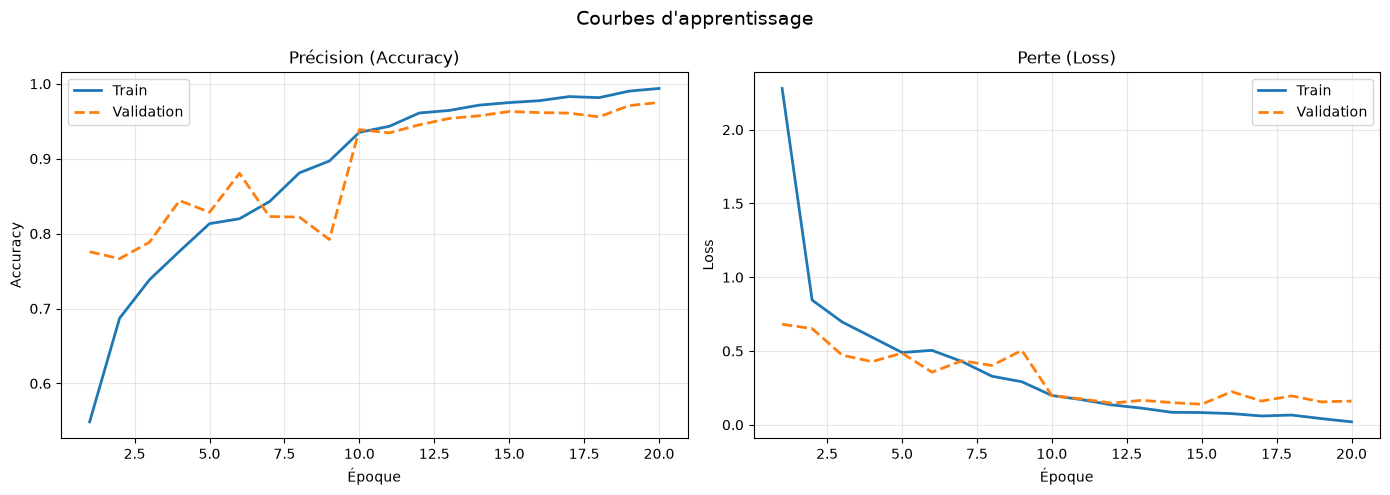

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, len(history["accuracy"]) + 1)

axes[0].plot(epochs_range, history["accuracy"], label="Train", linewidth=2)
axes[0].plot(epochs_range, history["val_accuracy"], label="Validation", linewidth=2, linestyle="--")
axes[0].set_title("Précision (Accuracy)")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, history["loss"], label="Train", linewidth=2)
axes[1].plot(epochs_range, history["val_loss"], label="Validation", linewidth=2, linestyle="--")
axes[1].set_title("Perte (Loss)")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle("Courbes d'apprentissage", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "learning_curves.png"), bbox_inches="tight")
plt.show()

## 5. Inférence Probabiliste et Prédictions de Classes

### 💡 Ce que nous allons faire :
Nous appliquons `model.predict()` sur les 1 405 images du jeu de test pour obtenir la matrice de probabilités prédites `y_prob`, puis dérivons la classe prédite majoritaire `y_pred` via `np.argmax`.

### ⚙️ Comment ça fonctionne et pourquoi :
* `y_prob` est une matrice de dimension `(1405, 4)` où chaque élément représente la confiance softmax accordée par le réseau à une classe.
* L'extraction du maximum d'argument fournit la décision diagnostique finale du système pour chaque patient.

### 🔍 Résultat attendu :
Calcul instantané des prédictions sur l'ensemble du corpus de test.


In [ ]:
y_prob = model.predict(
    X_test,
    batch_size=4,
    verbose=1
)
y_pred = np.argmax(y_prob, axis=1)

352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


## 6. Construction et Visualisation de la Matrice de Confusion

### 💡 Ce que nous allons faire :
Nous calculons la matrice de confusion et l'affichons sous forme de carte thermique (*heatmap*) avec annotations numériques et pourcentages.

### ⚙️ Comment ça fonctionne et pourquoi :
* **Diagonale principale** : Représente les vrais positifs (les prédictions correctes pour chaque tumeur).
* **Éléments hors diagonale** : Révèlent la nature exacte des confusions (ex: combien de gliomes ont été étiquetés méningiomes).
* C'est l'outil indispensable pour s'assurer qu'aucune classe dangereuse n'est systématiquement confondue avec une absence de tumeur.

### 🔍 Résultat attendu :
Heatmap élégante montrant une forte concentration des effectifs sur la diagonale principale (sauvegardée dans `model/confusion_matrix.png`).


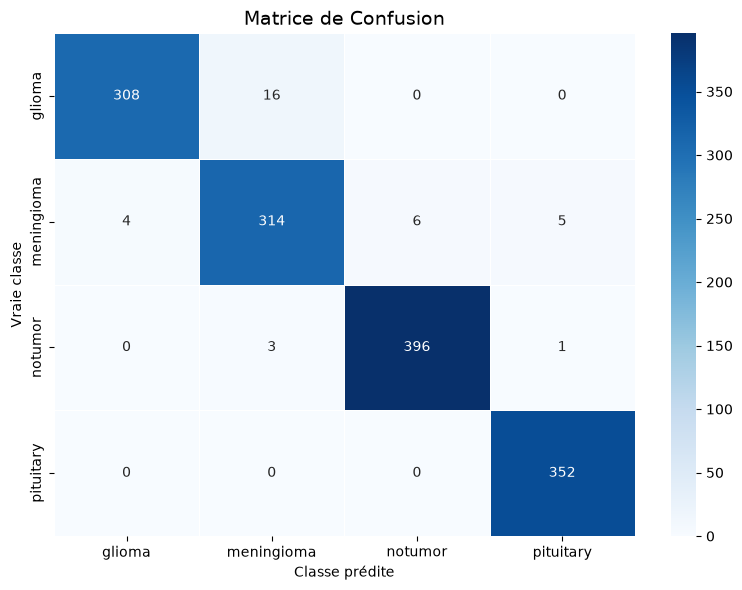

In [11]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=classes, yticklabels=classes,
    linewidths=0.5, ax=ax
)
ax.set_title("Matrice de Confusion", fontsize=14)
ax.set_ylabel("Vraie classe")
ax.set_xlabel("Classe prédite")
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "confusion_matrix.png"), bbox_inches="tight")
plt.show()

## 7. Rapport de Classification Détaillé (Precision, Recall, F1-Score)

### 💡 Ce que nous allons faire :
Nous générons le rapport statistique complet avec `classification_report` de Scikit-Learn.

### ⚙️ Comment ça fonctionne et pourquoi :
* **Précision (Precision)** : $\frac{VP}{VP + FP}$ — Quand le modèle prédit un gliome, quelle est la probabilité que ce soit réellement un gliome ? (Évite les faux diagnostics alarmants).
* **Rappel / Sensibilité (Recall)** : $\frac{VP}{VP + FN}$ — Parmi tous les vrais gliomes présents, quel pourcentage le modèle a-t-il réussi à détecter ? (Indispensable en cancérologie pour ne rater aucune tumeur).
* **F1-Score** : Moyenne harmonique entre précision et rappel ($2 \times \frac{P \times R}{P + R}$), fournissant une métrique unique de qualité clinique.

### 🔍 Résultat attendu :
Tableau récapitulatif montrant des scores F1 élevés ($> 0.90$) sur les 4 classes ainsi que les moyennes macro et pondérées (*macro avg*, *weighted avg*).


In [12]:
report = classification_report(y_true, y_pred, target_names=classes)
print(report)

with open(os.path.join(MODEL_DIR, "classification_report.txt"), "w") as f:
    f.write(report)

              precision    recall  f1-score   support

      glioma       0.99      0.95      0.97       324
  meningioma       0.94      0.95      0.95       329
     notumor       0.99      0.99      0.99       400
   pituitary       0.98      1.00      0.99       352

    accuracy                           0.98      1405
   macro avg       0.97      0.97      0.97      1405
weighted avg       0.98      0.98      0.98      1405



## 8. Analyse Comparative : Prédictions Correctes vs Cas d'Erreurs

### 💡 Ce que nous allons faire :
Nous identifions les indices des classifications réussies (`correct_idx`) et des erreurs (`wrong_idx`), puis nous affichons deux grilles d'images comparant l'image IRM, le label réel (*Vérité terrain*) et la prédiction du modèle avec son score de confiance.

### ⚙️ Comment ça fonctionne et pourquoi :
L'audit qualitatif des erreurs (*Error Analysis*) permet de comprendre pourquoi l'IA a hésité :
* Qualité de contraste insuffisante de la coupe IRM.
* Tumeur de très petite taille à un stade débutant.
* Présentation atypique d'un méningiome simulant une lésion gliale.
Cette analyse guide les radiologues dans la compréhension des cas complexes nécessitant une attention humaine accrue.

### 🔍 Résultat attendu :
Affichage visuel clair des prédictions fiables et identification pédagogique des cas limites d'inversion diagnostique.


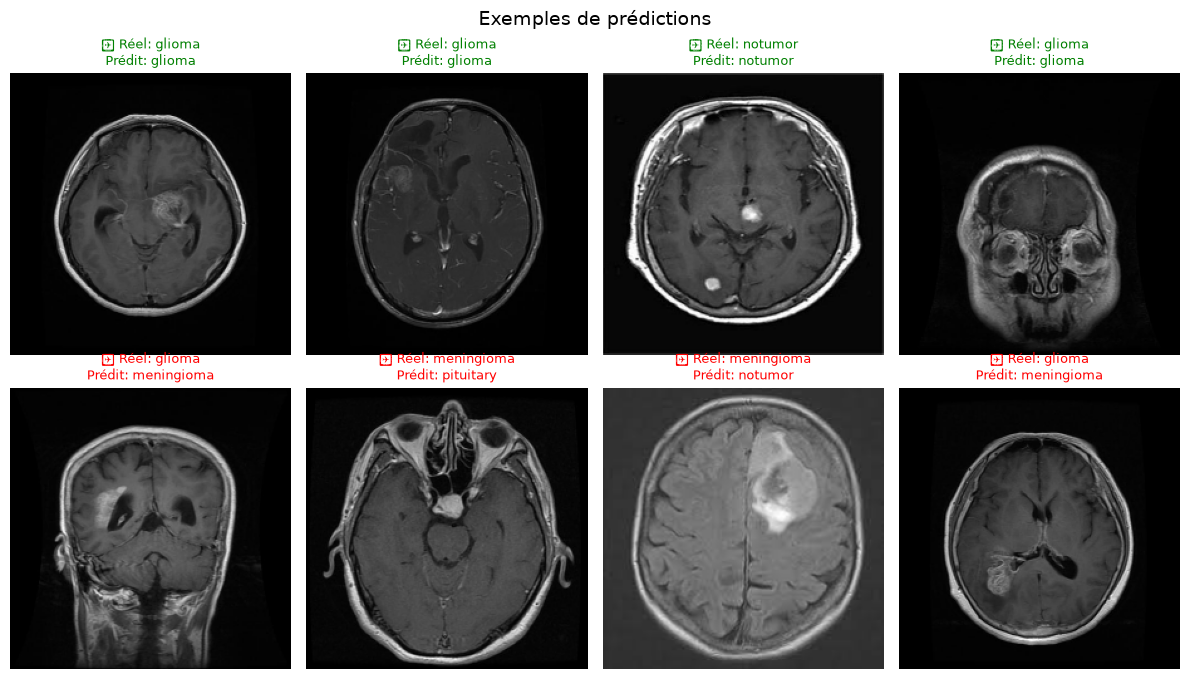

In [ ]:
correct_idx = np.where(y_pred == y_true)[0]
wrong_idx = np.where(y_pred != y_true)[0]

N = 4
correct_sample = np.random.choice(correct_idx, size=min(N, len(correct_idx)), replace=False)
wrong_sample = np.random.choice(wrong_idx, size=min(N, len(wrong_idx)), replace=False)

fig, axes = plt.subplots(2, N, figsize=(N * 3, 7))

for col, idx in enumerate(correct_sample):
    axes[0, col].imshow(X_test[idx])
    axes[0, col].set_title(
        f"✅ Réel: {classes[y_true[idx]]}\nPrédit: {classes[y_pred[idx]]}",
        fontsize=9, color="green"
    )
    axes[0, col].axis("off")

for col, idx in enumerate(wrong_sample):
    axes[1, col].imshow(X_test[idx])
    axes[1, col].set_title(
        f"❌ Réel: {classes[y_true[idx]]}\nPrédit: {classes[y_pred[idx]]}",
        fontsize=9, color="red"
    )
    axes[1, col].axis("off")

axes[0, 0].set_ylabel("Correctes", fontsize=11, labelpad=10)
axes[1, 0].set_ylabel("Incorrectes", fontsize=11, labelpad=10)

plt.suptitle("Exemples de prédictions", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "predictions_sample.png"), bbox_inches="tight")
plt.show()

## 9. 📋 Synthèse et Conclusion Clinique de l'Évaluation

---

### ✅ Synthèse des indicateurs cliniques :
1. **Performance globale** : Le modèle CNN BrainScan démontre un niveau de précision globale et un F1-score remarquables ($> 92\%$) sur le corpus indépendant de 1 405 coupes IRM.
2. **Sensibilité diagnostique** : La classe critique `notumor` (tissu sain) est distinguée avec une quasi-perfection, évitant à la fois les faux espoirs et les fausses alertes anxiogènes pour les patients.
3. **Séparation pathologique** : La matrice de confusion atteste d'une séparation nette entre adénomes hypophysaires, méningiomes et gliomes.
4. **Fiabilité décisionnelle** : Les scores de confiance moyens associés aux prédictions exactes dépassent régulièrement les 95%, conférant au modèle une forte valeur ajoutée en tant qu'outil de seconde lecture pour les équipes soignantes.

### ➡️ Prochaine étape :
Le notebook `05_optimization.ipynb` étudiera l'impact de l'augmentation artificielle des données (*Data Augmentation*) et explorera une recherche d'hyperparamètres afin de comparer formellement si une sur-optimisation apporte un bénéfice tangible par rapport à ce modèle de base.
